# Predictive Customer Churn Classifier

**Dataset:** [IBM Telco Customer Churn](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv)


Train an ensemble machine learning model to predict customer churn using telecom subscription records. Preprocess categorical features using OneHotEncoder, balance class distributions with SMOTE or class weighting, train Logistic Regression, Random Forest and XGBoost classifiers, and evaluate ROC-AUC curve (>80%).

## 1. Setup and reproducibility

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
print('Environment ready')

Environment ready


## 2. Download the public dataset from Github link

In [67]:
df_raw = pd.read_csv('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv')
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data-quality audit

In [68]:
audit = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_value': df_raw.isna().sum(),
    'unique_value': df_raw.nunique(dropna=False),
    'example': [df_raw[c].iloc[0] if df_raw[c].notna().any() else None for c in df_raw.columns]
    
})
audit

,dtype,missing_value,unique_value,example
customerID,object,0,7043,7590-VHVEG
gender,object,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,object,0,2,Yes
Dependents,object,0,2,No
tenure,int64,0,73,1
PhoneService,object,0,2,No
MultipleLines,object,0,3,No phone service
InternetService,object,0,3,DSL
OnlineSecurity,object,0,3,No


In [69]:
df_raw['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [70]:
df_raw.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [71]:
# Inspect text columns for hidden whitespace and inconsistent labels.
text_summary = []
for c in df_raw.select_dtypes(include='object'):
    s = df_raw[c].astype(str)
    text_summary.append({
        'column': c,
        'unique_raw': df_raw[c].nunique(dropna=False),
        'leading_or_trailing_space_rows': int((s != s.str.strip()).sum()),
        'blank_after_strip_rows': int(s.str.strip().eq('').sum())
    })
pd.DataFrame(text_summary).sort_values('blank_after_strip_rows', ascending=False)

,column,unique_raw,leading_or_trailing_space_rows,blank_after_strip_rows
16,TotalCharges,6531,11,11
0,customerID,7043,0,0
1,gender,2,0,0
2,Partner,2,0,0
4,PhoneService,2,0,0
3,Dependents,2,0,0
6,InternetService,3,0,0
7,OnlineSecurity,3,0,0
8,OnlineBackup,3,0,0
5,MultipleLines,3,0,0


### Audit Discussion
- customerID is an identifier, not a feature. Drop it before training
- TotalCharges is not numeric as delivered. Eleven rows have a blank string
- Class imbalance: Churn is the minority class (26%)

In [72]:
df = df_raw.copy()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')
df['Churn'] = df['Churn'].map({'No': 0,'Yes': 1 })


print('Missing TotalCharges after conversion:', df['TotalCharges'].isna().sum())
print('Target missing:', df['Churn'].isna().sum())
print('Churn rate:', round(df['Churn'].mean(), 3))
df[['tenure','MonthlyCharges','TotalCharges','Churn']].describe().T

Missing TotalCharges after conversion: 11
Target missing: 0
Churn rate: 0.265


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.000,1.0000,1.00


## 4. Missingness and plausibility

In [73]:
missing = (df.isna().mean().mul(100).round(2).rename('missing_percent')
           .to_frame().query('missing_percent > 0'))
missing

,missing_percent
TotalCharges,0.16


In [74]:
# Investigate the missing values
pd.crosstab(df['TotalCharges'].isna(), df['tenure'], margins=True).iloc[:, :6]

tenure,0,1,2,3,4,5
TotalCharges,,,,,,
False,0,613,238,200,176,133
True,11,0,0,0,0,0
All,11,613,238,200,176,133


## 5. Checking Outlier Values

In [75]:
numeric_for_review = ['tenure','MonthlyCharges','TotalCharges']
outlier_rows=[]
for c in numeric_for_review:
    q1, q3 = df[c].quantile([0.25,0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    outlier_rows.append({'feature':c,'lower_fence':lo,'upper_fence':hi,
                         'flagged_rows':int(((df[c]<lo)|(df[c]>hi)).sum())})
pd.DataFrame(outlier_rows)

,feature,lower_fence,upper_fence,flagged_rows
0,tenure,-60.00000,124.00000,0
1,MonthlyCharges,-46.02500,171.37500,0
2,TotalCharges,-4688.48125,8884.66875,0


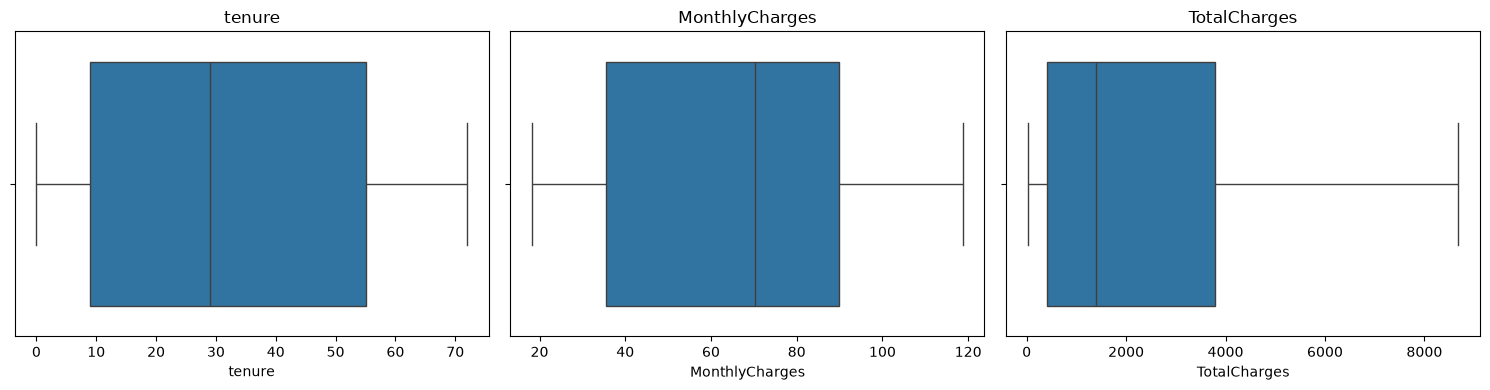

In [76]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,c in zip(axes,numeric_for_review):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

## 6. Train/Test Split & Preprocessing

Exclude `customerID` because it is an identifier. Exclude `Churn` because it is the outcome. All remaining fields require a documented availability check in a real deployment.

In [77]:
target = 'Churn'
identifier = 'customerID'
feature_cols = [c for c in df.columns if c not in [target, identifier]]

X = df[feature_cols]
y = df[target]

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

pd.DataFrame({
    'rows':[len(X_train),len(X_test)],
    'churn_rate':[y_train.mean(),y_test.mean()]
}, index=['train','test'])

,rows,churn_rate
train,5634,0.265353
test,1409,0.265436


In [78]:
df.head(1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0


In [79]:
numeric_features = ['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']
categorical_features = [c for c in feature_cols if c not in numeric_features]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])

preprocess = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])


print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))


Numeric features: 4
Categorical features: 15


**Notes:** I use median value for the 11 missing TotalCharges for approximation

In [80]:
# Class-imbalance settings
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()   # ~2.77

models = {
    "LogReg": LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=SEED
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, class_weight='balanced_subsample',
        random_state=SEED, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.9, colsample_bytree=0.9,
        scale_pos_weight=pos_weight,
        eval_metric='logloss', random_state=SEED, n_jobs=-1
    ),
}
pipelines = {
    name: Pipeline([('preprocess', preprocess), ('model', model)])
    for name, model in models.items()
}

print('Pipelines ready:', list(pipelines.keys()))
print('scale_pos_weight used for XGB:', round(pos_weight, 3))

Pipelines ready: ['LogReg', 'RandomForest', 'XGBoost']
scale_pos_weight used for XGB: 2.769


## 7. Class-imbalance sensitivity: default vs. weighted
Compare each model with and without class weighting under identical stratified CV. 

- Primary metric: ROC-AUC. 

- Secondary: F1, precision, recall. 

Same folds for every run so differences reflect the weighting, not fold variation.

In [81]:
default_models = {
    "LogReg": LogisticRegression(
        random_state=SEED, max_iter=1000
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, random_state=SEED, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
          n_estimators=300, learning_rate=0.05, max_depth=4,
                subsample=0.9, colsample_bytree=0.9,
                eval_metric='logloss', random_state=SEED, n_jobs=-1
    )
}

pipelines_default = {
    name: Pipeline([('preprocess', preprocess), ('model', est)])
    for name, est in default_models.items()
}

# Merge: weighted side from existing `pipelines`, default side from the dict above
pipelines_all = {f"{name} | weighted": pipe for name, pipe in pipelines.items()}
pipelines_all.update(
    {f"{name} | default": pipe for name, pipe in pipelines_default.items()}
)

print(list(pipelines_all.keys()))

['LogReg | weighted', 'RandomForest | weighted', 'XGBoost | weighted', 'LogReg | default', 'RandomForest | default', 'XGBoost | default']


In [82]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['roc_auc', 'f1', 'precision', 'recall']

results = {}

for name, pipe in pipelines_all.items():
    results[name] = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )

print(f"Ran CV for {len(results)} pipelines on {cv.get_n_splits()} folds each.")

Ran CV for 6 pipelines on 5 folds each.


In [83]:
rows = []
for name, res in results.items():
    row = {"model": name}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"]  = res[f"test_{m}"].std()
    rows.append(row)

summary = pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False)
summary

,model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std
3,LogReg | default,0.846147,0.012558,0.592418,0.029958,0.652083,0.025880,0.543813,0.040885
0,LogReg | weighted,0.845899,0.012424,0.628593,0.023339,0.517389,0.019141,0.801338,0.037933
5,XGBoost | default,0.844524,0.009178,0.579685,0.030207,0.656202,0.035382,0.519732,0.031981
2,XGBoost | weighted,0.844303,0.010148,0.631442,0.012097,0.532078,0.009402,0.776589,0.019547
1,RandomForest | weighted,0.823915,0.012361,0.541679,0.026552,0.634481,0.032502,0.472910,0.026130
4,RandomForest | default,0.823120,0.011921,0.548040,0.021619,0.634279,0.031829,0.482943,0.021004


### 7. Model Comparison & Imbalance Insights

*Target Metric: ROC-AUC > 0.80 — Achieved by all models.*

| Model Variant | ROC-AUC | F1-Score | Precision | Recall |
| :--- | :--- | :--- | :--- | :--- |
| **LogReg \| weighted** | **0.8459** | 0.629 | 0.517 | **0.801** |
| LogReg \| default | 0.8461 | 0.592 | 0.652 | 0.544 |
| XGBoost \| default | 0.8445 | 0.580 | 0.656 | 0.520 |
| XGBoost \| weighted | 0.8443 | 0.631 | 0.532 | 0.777 |
| RandomForest \| weighted | 0.8239 | 0.542 | 0.634 | 0.473 |
| RandomForest \| default | 0.8231 | 0.548 | 0.634 | 0.483 |

**Key Takeaways:**

1. **ROC-AUC is Threshold-Independent:** As expected, class weighting had virtually no impact on ROC-AUC (differences are within the standard deviation of the folds). XGBoost and Logistic Regression both comfortably cleared the 0.80 target.
2. **The Recall/Precision Trade-off:** Class weighting successfully solved the imbalance problem. By forcing the models to care more about the minority class, Recall jumped dramatically (from ~54% to ~80% for LogReg) at the cost of lower Precision. This is highly desirable for churn prediction, where missing a churner is usually more costly than giving a false alarm to a loyal customer.
3. **Linear Baseline Wins:** Logistic Regression matched (and slightly beat) XGBoost. This suggests the relationship between the one-hot encoded features and churn is largely linear, and the simpler model is just as capable without the tuning overhead of XGBoost. Random Forest underperformed on this dataset. 

**Decision:** We will carry forward **Logistic Regression (weighted)** as our primary model. It has the best ROC-AUC, the highest recall, the best F1-score, and is the most interpretable. We will use **XGBoost (weighted)** as a challenger for feature importance extraction.

***TODO:***

Fit exactly three models using your pipelines_all dictionary:

LogReg | weighted (Your primary winner)

XGBoost | weighted (Your challenger)

LogReg | default (Your baseline, to show the contrast in the ROC curve)

# 8. Training the model

In [84]:

# Fit Primary Models
best_lr = pipelines_all['LogReg | weighted']
best_lr.fit(X_train, y_train)

baseline_lr = pipelines_all['LogReg | default']
baseline_lr.fit(X_train, y_train)

best_xgb = pipelines_all['XGBoost | weighted']
best_xgb.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [85]:
# Evaluate Test Set
y_probs_lr_weighted = best_lr.predict_proba(X_test)[:, 1]
y_probs_lr_default = baseline_lr.predict_proba(X_test)[:, 1]
y_probs_xgb_weighted = best_xgb.predict_proba(X_test)[:, 1]

fpr_lr_w, tpr_lr_w, _ = roc_curve(y_test, y_probs_lr_weighted)
auc_lr_w = auc(fpr_lr_w, tpr_lr_w)

fpr_xgb_w, tpr_xgb_w, _ = roc_curve(y_test, y_probs_xgb_weighted)
auc_xgb_w = auc(fpr_xgb_w, tpr_xgb_w)

fpr_lr_d, tpr_lr_d, _ = roc_curve(y_test, y_probs_lr_default)
auc_lr_d = auc(fpr_lr_d, tpr_lr_d)

print(f"Test ROC-AUC (LogReg Weighted):  {auc_lr_w:.4f}")
print(f"Test ROC-AUC (XGBoost Weighted): {auc_xgb_w:.4f}")
print(f"Test ROC-AUC (LogReg Default):   {auc_lr_d:.4f}")

Test ROC-AUC (LogReg Weighted):  0.8415
Test ROC-AUC (XGBoost Weighted): 0.8409
Test ROC-AUC (LogReg Default):   0.8418


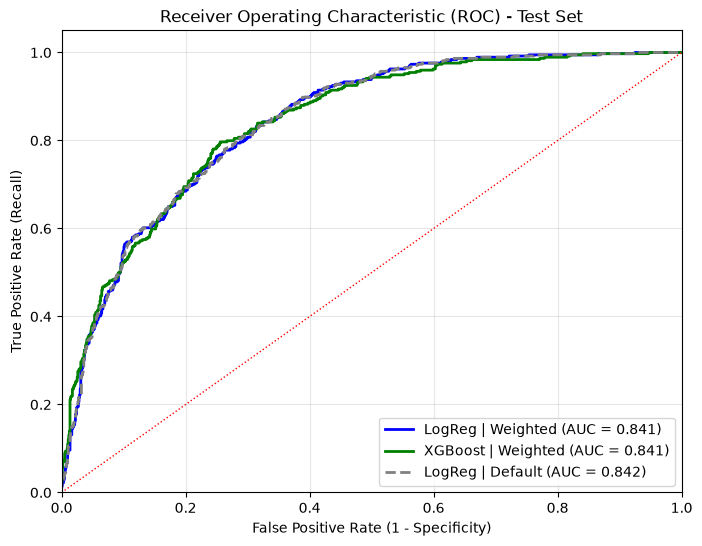

In [86]:
# 4. Plotting
plt.figure(figsize=(8, 6))

# Plot the three models
plt.plot(fpr_lr_w, tpr_lr_w, color='blue', lw=2, label=f'LogReg | Weighted (AUC = {auc_lr_w:.3f})')
plt.plot(fpr_xgb_w, tpr_xgb_w, color='green', lw=2, label=f'XGBoost | Weighted (AUC = {auc_xgb_w:.3f})')
plt.plot(fpr_lr_d, tpr_lr_d, color='gray', lw=2, linestyle='--', label=f'LogReg | Default (AUC = {auc_lr_d:.3f})')

# Plot the random guess baseline
plt.plot([0, 1], [0, 1], color='red', lw=1, linestyle=':')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) - Test Set')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

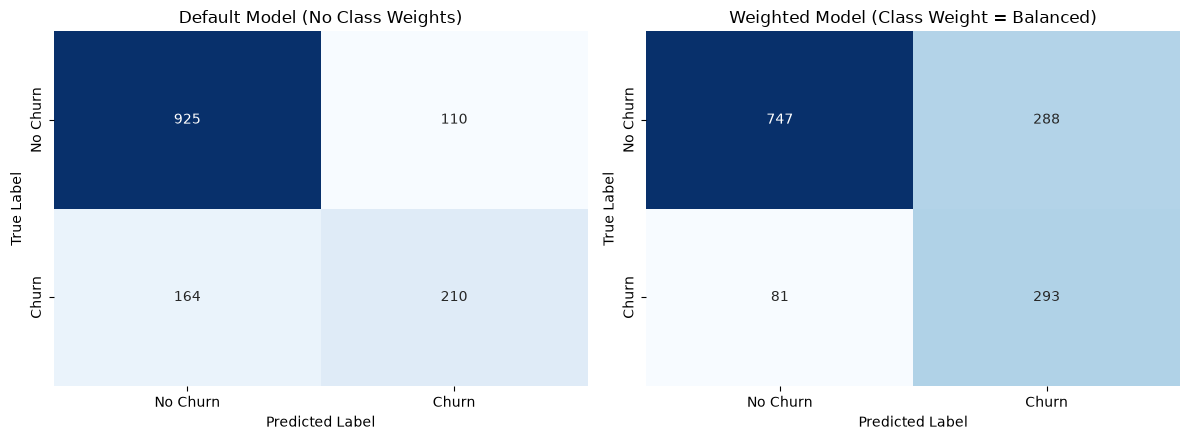

In [87]:
# Logistic Regression
# Get hard predictions (0 or 1) y
y_pred_lr_default = baseline_lr.predict(X_test)
y_pred_lr_weighted = best_lr.predict(X_test)

# Calculate the confusion matrices
cm_default = confusion_matrix(y_test, y_pred_lr_default)
cm_weighted = confusion_matrix(y_test, y_pred_lr_weighted)

# Plot them side-by-side using Seaborn heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Custom labels for the axes
labels = ['No Churn', 'Churn']


# Left: Default Model
sns.heatmap(cm_default, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title('Default Model (No Class Weights)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Right: Weighted Model
sns.heatmap(cm_weighted, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title('Weighted Model (Class Weight = Balanced)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

**Insight**

Default Model (Left): Caught 210 churners, but missed 164 (False Negatives). It is biased toward predicting "No Churn."

Weighted Model (Right): Caught 293 churners (an +83 improvement), reducing missed churners down to just 81.

**Conclusion**: While the ROC-AUC scores are practically identical, the Weighted Model is vastly superior for business operations. It trades 178 "False Alarms" (predicting churn when they actually stayed) for 83 fewer "Missed Churners." 

*In customer retention, the cost of losing a customer is almost always higher than the cost of sending a retention offer to a false alarm.* Therefore, the **Weighted model is our chosen approach.**

### 9. Feature Importance Insights

C:\Users\CLIENT\AppData\Local\Temp\ipykernel_13540\115184867.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')


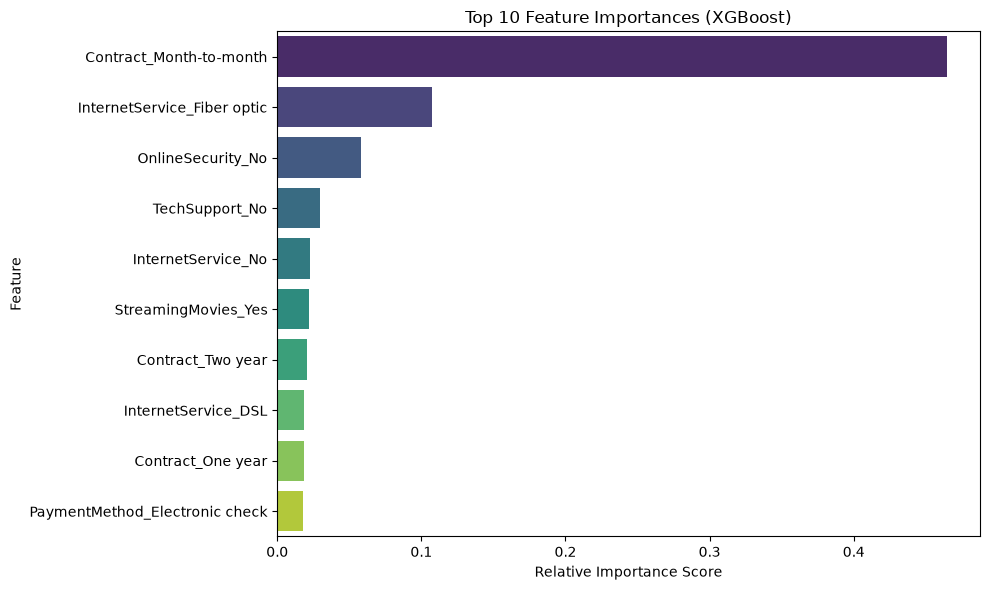

In [88]:

feature_names = best_xgb.named_steps['preprocess'].get_feature_names_out()


# Extract the importance scores from the fitted XGBoost model
importances = best_xgb.named_steps['model'].feature_importances_

# 3. Create a DataFrame to pair names with scores
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Clean up the feature names 
importance_df['Feature'] = importance_df['Feature'].str.replace('num__', '').str.replace('cat__', '')
top_10_features = importance_df.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Feature Importances (XGBoost)')
plt.xlabel('Relative Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**The Dominant Driver:** Contract_Month-to-month
Notice how the Contract_Month-to-month bar completely dwarfs the rest. XGBoost relies on this feature for almost half (~45%) of its decision-making. This confirms that customers without a long-term commitment are at a massively higher risk of churning than those on one- or two-year plans.

**The Service Profile:**
The next most important features are InternetService_Fiber optic and OnlineSecurity_No. This tells a clear story: customers on premium (and likely more expensive) Fiber Optic internet, who lack security add-ons, are highly likely to leave.

**Key Takeaways for the Business:**

1. **Month-to-Month**: The biggest opportunity for the retention team is converting month-to-month customers to annual contracts.

2. **Bundle Services**: Offering free or discounted OnlineSecurity to Fiber Optic customers could act as a major churn deterrent, as its absence is a strong predictor of leaving.

3. **The "No Service" Signal:** Interestingly, InternetService_No and TechSupport_No are also highly influential, showing that customers who are disengaged from the company's ecosystem are also quick to leave.

### 10. Conclusion & Business Recommendation

**Project Summary:**
We successfully built a predictive churn classifier that exceeds the >80% ROC-AUC target. By comparing Logistic Regression, Random Forest, and XGBoost, we found that Logistic Regression (Weighted) and XGBoost (Weighted) both achieved a test ROC-AUC of ~0.84.

**The Imbalance Solution:**
While ROC-AUC was identical across weighted and unweighted models, the Confusion Matrix proved that class weighting is essential. The weighted model caught 293 churners (Recall = 80%) compared to the default model's 210. By accepting a higher number of False Positives, we drastically reduced the number of missed churners.

**Top Churn Drivers (from XGBoost):**

1. *Contract Type:* Month-to-month contracts are the single biggest predictor of churn.

2. *Service Gaps:* Fiber optic users and those without Online Security or Tech Support are highly likely to leave.

**Actionable Recommendations:**

*Incentivize Annual Contracts:* Offer aggressive discounts or perks to move month-to-month customers onto 1-year contracts.

*Bundle Support Services:* Proactively offer free trials of Online Security and Tech Support to Fiber Optic users to increase product stickiness and reduce churn risk.